# 07 - StreetCLIP: zero-shot vs linear probe vs fine-tuned (Louis)

Reads the exported logits in `predictions/` (team format) and answers one question: **is the fine-tuned model
the final StreetCLIP model, or do we keep the linear probe?** The rule was fixed in advance (notebook 06, section 0):
fine-tuned wins only if it beats the probe on **val macro-F1** by more than the bootstrap noise.

Every model whose file exists is included; missing ones (`cnn_scratch`, `resnet50`, `streetclip_finetuned` today)
are skipped, so this notebook needs no change when they appear. Everything here is on **val**, except the last
section, which stays off (`FINAL = False`) until the very end. This is our decision tool; the official metrics
(incl. distance error in km, reliability diagrams) are in Maya's evaluation module.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from geosense import compare, load_classes, load_continents, load_manifest
from geosense.data import PROJECT_ROOT
from geosense.predictions import MODEL_NAMES, PRED_DIR

# --- configuration ---------------------------------------------------------------------------
FINAL = False                  # True ONCE at the very end (after the team agrees): also report test
INCLUDE_RUNS = True            # also show experiment exports from predictions/runs/ (val only)
N_BOOT = 1000                  # bootstrap resamples
FIG_DIR = PROJECT_ROOT / "results"
# ---------------------------------------------------------------------------------------------
ZS, PROBE, FT = "streetclip_zeroshot", "streetclip_probe", "streetclip_finetuned"
classes, _ = load_classes()
continents = load_continents()
val = load_manifest(split="val")
y = val.label.to_numpy()

logits = compare.load_available_logits(PRED_DIR, MODEL_NAMES, "val", n_rows=len(y))
if INCLUDE_RUNS and (PRED_DIR / "runs").is_dir():
    run_names = sorted(f.name[:-len("_val_logits.npy")] for f in (PRED_DIR / "runs").glob("*_val_logits.npy"))
    logits |= {f"run:{k}": v for k, v in compare.load_available_logits(PRED_DIR / "runs", run_names, "val", len(y)).items()}
print("val images:", len(y), "| models found:", list(logits))
print("missing:", [m for m in MODEL_NAMES if m not in logits])

# one fixed colour + marker per model, used in every figure
COLOUR = {"majority": "#9e9e9e", "histogram_lr": "#8c6d31", "histogram_rf": "#bd9e39", "cnn_scratch": "#7b4173",
          "resnet50": "#a55194", ZS: "#1f77b4", PROBE: "#ff7f0e", FT: "#2ca02c"}
MARKER = {ZS: "o", PROBE: "s", FT: "^"}
LABEL = {ZS: "zero-shot", PROBE: "linear probe", FT: "fine-tuned"}
colour = lambda m: COLOUR.get(m, "#555555")
clip_models = [m for m in (ZS, PROBE, FT) if m in logits]

val images: 7171 | models found: ['majority', 'histogram_lr', 'histogram_rf', 'streetclip_zeroshot', 'streetclip_probe']
missing: ['cnn_scratch', 'resnet50', 'streetclip_finetuned']


## 1. Summary table (val)
- **top1 / top5**: correct country first / in the 5 most likely.
- **macro_f1**: average F1 over the 56 countries, every country weighs the same (our primary metric).
- **continent_acc**: continent probability = **sum** of its country probabilities (team rule), then the most likely
  continent. It can be right when the country is wrong (Belgium for France).
- **nll** and **mean_conf**: a first look at calibration (section 4).

,top1,top5,macro_f1,continent_acc,nll,mean_conf
majority,0.250,0.505,0.007,0.366,3.174,0.250
histogram_lr,0.110,0.359,0.092,0.398,3.486,0.211
histogram_rf,0.232,0.560,0.119,0.391,3.081,0.101
streetclip_zeroshot,0.820,0.974,0.695,0.958,0.555,0.815
streetclip_probe,0.885,0.987,0.776,0.971,0.370,0.901


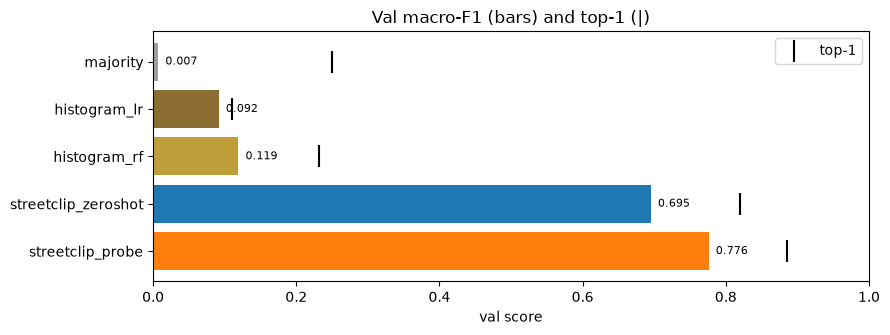

In [2]:
summary = compare.summary_table(logits, y, classes, continents)
display(summary.round(3))

order = list(summary.index)
fig, ax = plt.subplots(figsize=(9, 0.45 * len(order) + 1.2))
yy = np.arange(len(order))
ax.barh(yy, summary.macro_f1, color=[colour(m) for m in order])
ax.scatter(summary.top1, yy, marker="|", s=250, c="black", label="top-1", zorder=3)
for i, m in enumerate(order):
    ax.text(summary.macro_f1.iloc[i] + 0.01, i, f"{summary.macro_f1.iloc[i]:.3f}", va="center", fontsize=8)
ax.set(yticks=yy, yticklabels=order, xlabel="val score", title="Val macro-F1 (bars) and top-1 (|)", xlim=(0, 1))
ax.invert_yaxis(); ax.legend(loc="upper right")
fig.tight_layout(); fig.savefig(FIG_DIR / "ft_summary_val.png", dpi=150); plt.show()

## 2. Zero-shot vs probe vs fine-tuned: is the difference real?
With 7,171 val images (some countries have ~15), a gain of 0.01 can be luck. The **paired bootstrap** resamples the
val images 1,000 times, scores **both** models on the same resample, and keeps the 2.5–97.5% range of the
difference. If that interval contains 0, we cannot claim one model is better.

fine-tuned not available yet: only zero-shot vs probe below.


,comparison,metric,a,b,diff,low,high,significant
0,linear probe - zero-shot,macro_f1,0.7760,0.6952,0.0808,0.0644,0.0960,True
1,linear probe - zero-shot,top1,0.8851,0.8198,0.0653,0.0577,0.0731,True


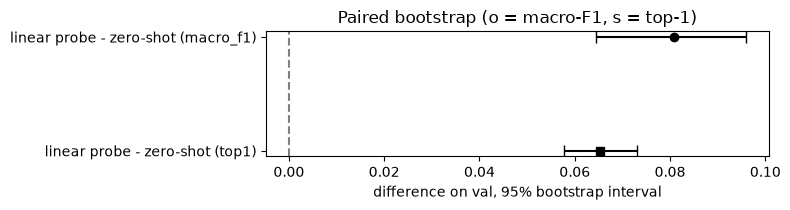

In [3]:
pairs = [(PROBE, ZS), (FT, PROBE), (FT, ZS)]
boot = []
for a, b in pairs:
    if a in logits and b in logits:
        for metric in ("macro_f1", "top1"):
            r = compare.paired_bootstrap(logits[a], logits[b], y, metric, n_boot=N_BOOT)
            boot.append({"comparison": f"{LABEL[a]} - {LABEL[b]}", **r})
boot = pd.DataFrame(boot)
if FT not in logits:
    print("fine-tuned not available yet: only zero-shot vs probe below.")
display(boot.round(4))

fig, ax = plt.subplots(figsize=(8, 0.6 * len(boot) + 1))
for i, r in boot.iterrows():
    ax.errorbar(r["diff"], i, xerr=[[r["diff"] - r.low], [r.high - r["diff"]]], fmt="o" if r.metric == "macro_f1" else "s",
                color="black", capsize=4)
ax.axvline(0, ls="--", c="grey")
ax.set(yticks=range(len(boot)), yticklabels=boot.comparison + " (" + boot.metric + ")",
       xlabel="difference on val, 95% bootstrap interval", title="Paired bootstrap (o = macro-F1, s = top-1)")
ax.invert_yaxis(); fig.tight_layout(); fig.savefig(FIG_DIR / "ft_bootstrap_val.png", dpi=150); plt.show()

## 3. Where does it help? Per continent and per country
Africa is the known weak point *in data*: 5 countries, ~3.5% of the images. Check whether it is also weak
in accuracy, and whether fine-tuning (which sees few African images) helps or hurts it. Per-group top-1 = share of that group's images whose
country is predicted correctly (per country, this is the recall).

,n_val,streetclip_zeroshot,streetclip_probe
group,,,
Africa,254,0.858,0.933
Oceania,338,0.914,0.920
South America,593,0.767,0.823
Asia,1220,0.892,0.933
North America,2138,0.867,0.945
Europe,2628,0.744,0.819


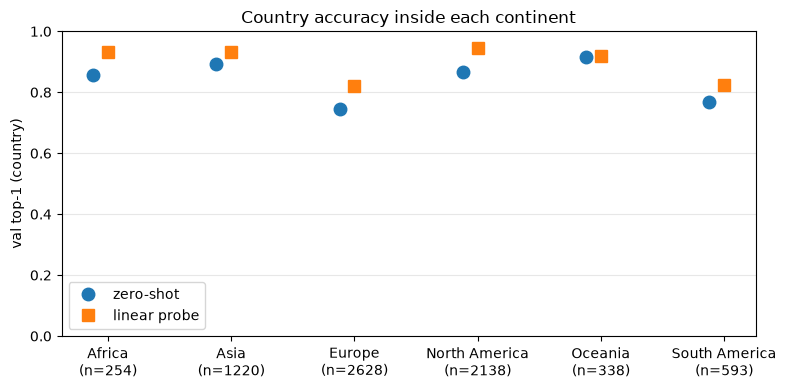

In [4]:
true_cont = np.array([continents[classes[i]] for i in y])
per_cont = pd.DataFrame({m: compare.per_group_accuracy(logits[m], y, true_cont).top1 for m in clip_models})
per_cont.insert(0, "n_val", compare.per_group_accuracy(logits[clip_models[0]], y, true_cont).n)
display(per_cont.sort_values("n_val").round(3))

fig, ax = plt.subplots(figsize=(8, 4))
xx = np.arange(len(per_cont))
for k, m in enumerate(clip_models):
    ax.plot(xx + (k - 1) * 0.12, per_cont[m], ls="none", marker=MARKER[m], ms=9, color=colour(m), label=LABEL[m])
ax.set(xticks=xx, xticklabels=[f"{c}\n(n={n})" for c, n in per_cont.n_val.items()], ylabel="val top-1 (country)",
       title="Country accuracy inside each continent", ylim=(0, 1))
ax.legend(); ax.grid(axis="y", alpha=0.3)
fig.tight_layout(); fig.savefig(FIG_DIR / "ft_continent_val.png", dpi=150); plt.show()

Countries that gained / lost most. The real question is probe → fine-tuned; until the fine-tuned file exists
we show zero-shot → probe, so the cell already works. Countries with few val images move a lot by chance: read
`n_val` before drawing conclusions.

In [5]:
old, new = (PROBE, FT) if FT in logits else (ZS, PROBE)
print(f"change in per-country recall: {LABEL[old]} -> {LABEL[new]}")
countries = np.array(classes)[y]
per_c = pd.DataFrame({"n_val": compare.per_group_accuracy(logits[old], y, countries).n,
                      LABEL[old]: compare.per_group_accuracy(logits[old], y, countries).top1,
                      LABEL[new]: compare.per_group_accuracy(logits[new], y, countries).top1})
per_c["change"] = per_c[LABEL[new]] - per_c[LABEL[old]]
per_c["continent"] = [continents[c] for c in per_c.index]
per_c = per_c.sort_values("change")
display(pd.concat([per_c.tail(8)[::-1], per_c.head(8)], keys=["gained most", "lost most"]).round(3))

change in per-country recall: zero-shot -> linear probe


n_val  zero-shot  linear probe  change      continent
            group                                                           
gained most Russia       263      0.559         0.852   0.293         Europe
            Czechia       38      0.211         0.500   0.289         Europe
            Lithuania     21      0.286         0.571   0.286         Europe
            Romania       52      0.615         0.865   0.250         Europe
            Peru          40      0.650         0.825   0.175  South America
            Finland      157      0.803         0.968   0.166         Europe
            Argentina    103      0.728         0.854   0.126  South America
            Thailand     141      0.759         0.879   0.121           Asia
lost most   Latvia        18      0.667         0.333  -0.333         Europe
            Ukraine       17      0.588         0.294  -0.294         Europe
            Belgium       33      0.636         0.364  -0.273         Europe
            Slovakia      16      0.688         0.438  -0.250         Europe
            Hungary       25      0.560         0.360  -0.200         Europe
            Colombia      38      0.658         0.500  -0.158  South America
            Portugal      37      0.784         0.676  -0.108         Europe
            Canada       207      0.947         0.841  -0.106  North America

## 4. Confidence: is the model too sure of itself?
A calibrated model that says "70%" is right 70% of the time, so its **mean confidence** (average max probability)
should be close to its **top-1**. Fine-tuning often pushes confidence up faster than accuracy (over-confidence); this
also raises the **NLL**. The app shows probabilities, so this matters. Maya's **temperature scaling** (fitted on val)
divides the logits by one number and fixes this **without changing any prediction**: top-1 / macro-F1, and therefore
the verdict below, stay the same.

,top1,mean_conf,nll,over_confidence
majority,0.250,0.250,3.174,-0.000
histogram_lr,0.110,0.211,3.486,0.101
histogram_rf,0.232,0.101,3.081,-0.131
streetclip_zeroshot,0.820,0.815,0.555,-0.005
streetclip_probe,0.885,0.901,0.370,0.016


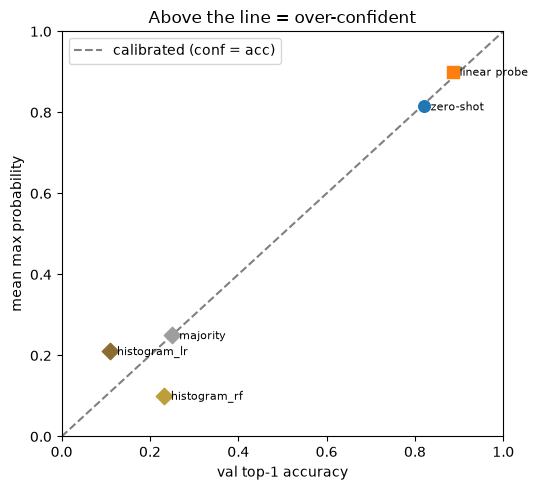

In [6]:
conf = summary[["top1", "mean_conf", "nll"]].assign(over_confidence=summary.mean_conf - summary.top1)
display(conf.round(3))

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot([0, 1], [0, 1], ls="--", c="grey", label="calibrated (conf = acc)")
for m in [m for m in summary.index if not m.startswith("run:")]:   # experiment runs: see the table
    ax.scatter(summary.top1[m], summary.mean_conf[m], color=colour(m), marker=MARKER.get(m, "D"), s=70, zorder=3)
    ax.annotate(LABEL.get(m, m), (summary.top1[m], summary.mean_conf[m]), fontsize=8, xytext=(5, -3), textcoords="offset points")
ax.set(xlabel="val top-1 accuracy", ylabel="mean max probability", xlim=(0, 1), ylim=(0, 1),
       title="Above the line = over-confident")
ax.legend(loc="upper left"); fig.tight_layout(); fig.savefig(FIG_DIR / "ft_confidence_val.png", dpi=150); plt.show()

## 5. Verdict (rule fixed in advance)
Fine-tuned is the final StreetCLIP model only if the 95% interval of (fine-tuned − probe) val macro-F1 is entirely above 0.

In [7]:
if FT not in logits:
    verdict = "fine-tuned not available yet"
else:
    r = compare.paired_bootstrap(logits[FT], logits[PROBE], y, "macro_f1", n_boot=N_BOOT)
    print(f"val macro-F1: fine-tuned {r['a']:.4f}, probe {r['b']:.4f}, "
          f"difference {r['diff']:+.4f} [95% {r['low']:+.4f}, {r['high']:+.4f}]")
    verdict = ("fine-tuned is the final StreetCLIP model" if r["low"] > 0
               else "keep the linear probe: fine-tuning did not beat it")
print("VERDICT:", verdict)

VERDICT: fine-tuned not available yet


## 6. Test (once, at the very end)
Only after the verdict above and after the team agrees. It reports the same table on test **once**; it must **not**
be used to choose anything (model, run, epoch, temperature): every choice is already made on val.

In [8]:
if not FINAL:
    print("FINAL = False: the test set is not touched.")
else:
    y_test = load_manifest(split="test").label.to_numpy()
    test_logits = compare.load_available_logits(PRED_DIR, MODEL_NAMES, "test", n_rows=len(y_test))
    print("TEST - report only, do not use to choose anything. Models:", list(test_logits))
    display(compare.summary_table(test_logits, y_test, classes, continents).round(3))

FINAL = False: the test set is not touched.
